# Plot homogeneous model forecasts and best track

This notebook plots one ATCF metric from several models for one initialization cycle. It accepts the metric, model list, cycle, A-deck filename, maximum lead time, and forecast interval.

Only homogeneous lead times are plotted: a lead is retained only when the selected metric exists for every requested model and for the matching B-deck valid time. This guarantees that every model is compared over exactly the same lead-time sample. The requested `lead_time` is included, so it must be an integer multiple of `hh`.

In [1]:
from __future__ import annotations

import re
from datetime import timedelta
from typing import Dict, List, Sequence, Tuple

import matplotlib.dates as mdates
import matplotlib.pyplot as plt

try:
    from src import mod_abdeck as abdeck
except ModuleNotFoundError as exc:
    if exc.name != "src":
        raise
    import mod_abdeck as abdeck

## Plotting function

Supported storm filenames begin with `aal`, `awp`, `aep`, or `acp`. Supported metrics are `VMAX`, `PMIN`, `RMW`, `R34`, `R50`, and `R64`. The returned `plot_data` dictionary contains the exact homogeneous data shown in the graph.

In [2]:
def plot_model_forecasts(
    metric: str,
    models: Sequence[str],
    cycle: str,
    storm: str,
    lead_time: int,
    hh: int,
    *,
    figsize: Tuple[float, float] = (11, 6),
) -> Tuple[plt.Figure, plt.Axes, Dict[str, List[float]]]:
    """Plot homogeneous model forecasts and corresponding best track.

    Parameters
    ----------
    metric : str
        One of VMAX, PMIN, RMW, R34, R50, or R64.
    models : sequence[str]
        Four-character ATCF model identifiers.
    cycle : str
        Forecast initialization cycle in yyyymmddhh format.
    storm : str
        A-deck filename such as aep172026.dat.
    lead_time : int
        Maximum plotted lead time in hours, included in the plot.
    hh : int
        Interval in hours between requested forecast points.

    Returns
    -------
    fig, ax, plot_data
        Matplotlib objects and the homogeneous values used in the plot.
    """
    metric = str(metric).strip().upper()
    storm = str(storm).strip().lower()
    if metric not in abdeck.SUPPORTED_METRICS:
        raise ValueError(
            f"metric must be one of {sorted(abdeck.SUPPORTED_METRICS)}."
        )
    if not isinstance(models, (list, tuple)) or not models:
        raise ValueError("models must be a non-empty list or tuple.")

    normalized_models = [str(model).strip().upper() for model in models]
    if any(
        not re.fullmatch(r"[A-Z0-9]{4}", model)
        for model in normalized_models
    ):
        raise ValueError(
            "Every model must be a four-character ATCF identifier."
        )
    if len(set(normalized_models)) != len(normalized_models):
        raise ValueError("models must not contain duplicates.")
    if re.fullmatch(r"a(al|wp|ep|cp)\d{2}\d{4}\.dat", storm) is None:
        raise ValueError(
            "storm must be an ATCF A-deck filename such as "
            "'aep172026.dat'."
        )
    if isinstance(hh, bool) or not isinstance(hh, int) or hh <= 0:
        raise ValueError("hh must be a positive integer.")
    if (
        isinstance(lead_time, bool)
        or not isinstance(lead_time, int)
        or lead_time < 0
    ):
        raise ValueError("lead_time must be a non-negative integer.")
    if lead_time % hh != 0:
        raise ValueError("lead_time must be an integer multiple of hh.")

    cycle_dt = abdeck._parse_cycle(cycle, "cycle")
    adeck_path = abdeck.ADECK_DIR / storm
    bdeck_path = abdeck.BDECK_DIR / f"b{storm[1:]}"
    if not adeck_path.is_file():
        raise FileNotFoundError(f"A-deck file not found: {adeck_path}")
    if not bdeck_path.is_file():
        raise FileNotFoundError(f"B-deck file not found: {bdeck_path}")

    forecast = abdeck._read_adeck_metric(
        adeck_path, metric, set(normalized_models)
    )
    best_track = abdeck._read_bdeck_metric(bdeck_path, metric)
    requested_leads = list(range(0, lead_time + 1, hh))
    common_leads = [
        tau
        for tau in requested_leads
        if cycle_dt + timedelta(hours=tau) in best_track
        and all(
            (cycle_dt, model, tau) in forecast
            for model in normalized_models
        )
    ]
    if not common_leads:
        raise ValueError(
            "No homogeneous lead times contain the selected metric for "
            "every model and the best track."
        )

    excluded_leads = [
        tau for tau in requested_leads if tau not in common_leads
    ]
    if excluded_leads:
        print(
            "Excluded non-homogeneous lead times (h):",
            excluded_leads,
        )

    plot_data: Dict[str, List[float]] = {
        "lead_hour": common_leads,
        "BEST": [
            best_track[cycle_dt + timedelta(hours=tau)]
            for tau in common_leads
        ],
    }
    for model in normalized_models:
        plot_data[model] = [
            forecast[(cycle_dt, model, tau)] for tau in common_leads
        ]

    expected_length = len(common_leads)
    if any(
        len(plot_data[name]) != expected_length
        for name in [*normalized_models, "BEST"]
    ):
        raise RuntimeError("The plotted series are not homogeneous.")

    units = {
        "VMAX": "kt",
        "PMIN": "hPa",
        "RMW": "n mi",
        "R34": "n mi",
        "R50": "n mi",
        "R64": "n mi",
    }
    fig, ax = plt.subplots(figsize=figsize)
    for model in normalized_models:
        ax.plot(
            common_leads,
            plot_data[model],
            marker="o",
            linewidth=1.8,
            label=model,
        )
    ax.plot(
        common_leads,
        plot_data["BEST"],
        color="black",
        marker="o",
        linewidth=3.5,
        label="Best track",
        zorder=10,
    )
    ax.set_title(
        f"{metric} forecast: {storm} initialized {cycle_dt:%Y-%m-%d %H UTC}"
    )
    ax.set_xlabel("Forecast lead time (h)",fontsize=14)
    ax.set_ylabel(f"{metric} ({units[metric]})",fontsize=14)
    ax.set_xticks([0,6,12,18,24,36,48,72,96,120])#common_leads)
    #ax.tick_params(axis="x", labelsize=16, labelrotation=0)
    ax.tick_params(axis='x', labelsize=16)
    ax.tick_params(axis='y', labelsize=16)
    ax.set_xlim(0,120)
    ax.set_ylim(0,210)
    ax.grid(True, alpha=0.3)
    ax.legend()
    fig.tight_layout()
    return fig, ax, plot_data

## Example of a cylce for Polo (17E), 2026

Edit these six inputs to plot a different metric, set of models, initialization cycle, storm, maximum lead time, or interval.

Homogeneous lead times (h): [0, 6, 12, 18, 24, 30, 36, 42, 48, 54, 60, 66, 72, 78, 84, 90, 96, 102, 108, 114, 120]


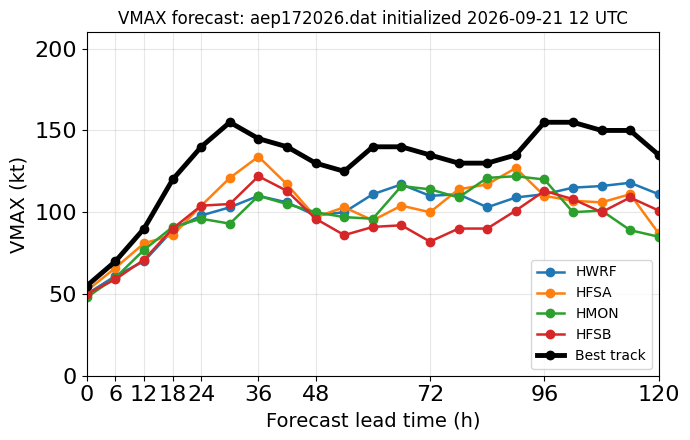

In [7]:
metric = "VMAX"
models = ["HWRF", "HFSA", "HMON", "HFSB"]
cycle = "2026092112"
storm = "aep172026.dat"
lead_time = 120
hh = 6

fig, ax, plot_data = plot_model_forecasts(
    metric=metric,
    models=models,
    cycle=cycle,
    storm=storm,
    lead_time=lead_time,
    hh=hh,
    figsize=(7,4.5))
print("Homogeneous lead times (h):", plot_data["lead_hour"])

## Composite of every forecast cycle for one model

This plot uses five inputs: `metric`, `model`, `storm`, `lead_time`, and `hh`. An initialization cycle is included when it occurs between the first and last timestamps in the B-deck storm life cycle. Each cycle has a different color and is plotted against its actual forecast valid times. Forecast points through `lead_time` are retained even when their valid times extend beyond the end of the B-deck. The available best-track metric is overlaid in thick black.

In [ ]:
def plot_model_cycle_composite(
    metric: str,
    model: str,
    storm: str,
    lead_time: int,
    hh: int,
    *,
    figsize: Tuple[float, float] = (14, 7),
) -> Tuple[plt.Figure, plt.Axes, Dict[str, object]]:
    """Plot every in-lifecycle forecast cycle from one model.

    Model forecasts are not truncated at the final B-deck time.
    ``lead_time`` is included and must be an integer multiple of ``hh``.
    """
    metric = str(metric).strip().upper()
    model = str(model).strip().upper()
    storm = str(storm).strip().lower()
    if metric not in abdeck.SUPPORTED_METRICS:
        raise ValueError(
            f"metric must be one of {sorted(abdeck.SUPPORTED_METRICS)}."
        )
    if re.fullmatch(r"[A-Z0-9]{4}", model) is None:
        raise ValueError("model must be a four-character ATCF identifier.")
    if re.fullmatch(r"a(al|wp|ep|cp)\d{2}\d{4}\.dat", storm) is None:
        raise ValueError(
            "storm must be an ATCF A-deck filename such as "
            "'aep172026.dat'."
        )
    if isinstance(hh, bool) or not isinstance(hh, int) or hh <= 0:
        raise ValueError("hh must be a positive integer.")
    if (
        isinstance(lead_time, bool)
        or not isinstance(lead_time, int)
        or lead_time < 0
    ):
        raise ValueError("lead_time must be a non-negative integer.")
    if lead_time % hh != 0:
        raise ValueError("lead_time must be an integer multiple of hh.")

    adeck_path = abdeck.ADECK_DIR / storm
    bdeck_path = abdeck.BDECK_DIR / f"b{storm[1:]}"
    if not adeck_path.is_file():
        raise FileNotFoundError(f"A-deck file not found: {adeck_path}")
    if not bdeck_path.is_file():
        raise FileNotFoundError(f"B-deck file not found: {bdeck_path}")

    bdeck_times = sorted(abdeck._read_bdeck_times(bdeck_path))
    if not bdeck_times:
        raise ValueError(f"No BEST-track timestamps found in {bdeck_path.name}.")
    lifecycle_start, lifecycle_end = bdeck_times[0], bdeck_times[-1]
    best_track = abdeck._read_bdeck_metric(bdeck_path, metric)
    if not best_track:
        raise ValueError(
            f"No valid {metric} best-track data found in {bdeck_path.name}."
        )

    forecast = abdeck._read_adeck_metric(adeck_path, metric, {model})
    initialization_cycles = sorted(
        {
            forecast_cycle
            for forecast_cycle, record_model, _ in forecast
            if record_model == model
            and lifecycle_start <= forecast_cycle <= lifecycle_end
        }
    )
    if not initialization_cycles:
        raise ValueError(
            f"No {model} {metric} forecast cycles occur during the "
            "B-deck life cycle."
        )

    requested_leads = list(range(0, lead_time + 1, hh))
    cycle_data: Dict[str, Dict[str, List]] = {}
    for initialization_cycle in initialization_cycles:
        available_leads = [
            tau
            for tau in requested_leads
            if (initialization_cycle, model, tau) in forecast
        ]
        if not available_leads:
            continue
        cycle_label = initialization_cycle.strftime("%Y%m%d%H")
        cycle_data[cycle_label] = {
            "lead_hour": available_leads,
            "valid_time": [
                initialization_cycle + timedelta(hours=tau)
                for tau in available_leads
            ],
            "value": [
                forecast[(initialization_cycle, model, tau)]
                for tau in available_leads
            ],
        }
    if not cycle_data:
        raise ValueError("No forecast data exist on the requested lead grid.")

    best_times = sorted(best_track)
    composite_data: Dict[str, object] = {
        "life_cycle": (lifecycle_start, lifecycle_end),
        "cycles": cycle_data,
        "BEST": {
            "valid_time": best_times,
            "value": [best_track[valid_time] for valid_time in best_times],
        },
    }

    units = {
        "VMAX": "kt",
        "PMIN": "hPa",
        "RMW": "n mi",
        "R34": "n mi",
        "R50": "n mi",
        "R64": "n mi",
    }
    fig, ax = plt.subplots(figsize=figsize)
    colors = plt.get_cmap("turbo", len(cycle_data))
    for color_index, (cycle_label, values) in enumerate(cycle_data.items()):
        ax.plot(
            values["valid_time"],
            values["value"],
            color=colors(color_index),
            marker="o",
            markersize=3,
            linewidth=1.3,
            alpha=0.85,
            label=cycle_label,
        )
    ax.plot(
        best_times,
        composite_data["BEST"]["value"],
        color="black",
        marker="o",
        markersize=4,
        linewidth=3.5,
        label="Best track",
        zorder=20,
    )
    ax.set_title(f"{model} {metric} forecasts for every cycle: {storm}")
    ax.set_xlabel("Forecast valid time (UTC)")
    ax.set_ylabel(f"{metric} ({units[metric]})")
    date_locator = mdates.AutoDateLocator(minticks=6, maxticks=12)
    ax.xaxis.set_major_locator(date_locator)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(date_locator))
    ax.grid(True, alpha=0.3)
    legend_columns = max(1, (len(cycle_data) + 14) // 15)
    ax.legend(
        title="Initialization cycle",
        bbox_to_anchor=(1.02, 1),
        loc="upper left",
        fontsize=7,
        ncol=legend_columns,
    )
    fig.tight_layout()
    return fig, ax, composite_data

## Composite example for Polo (17E), 2026

In [ ]:
composite_metric = "VMAX"
composite_model = "HWRF"
composite_storm = "aep172026.dat"
composite_lead_time = 120
composite_hh = 6

composite_fig, composite_ax, composite_data = plot_model_cycle_composite(
    metric=composite_metric,
    model=composite_model,
    storm=composite_storm,
    lead_time=composite_lead_time,
    hh=composite_hh,
)
print("B-deck life cycle:", composite_data["life_cycle"])
print("Forecast cycles plotted:", len(composite_data["cycles"]))